/tmp/ipykernel_22459/1741000336.py:11: Pandas4Warning: The inplace keyword in Series.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  prices.reset_index("order_book_id", inplace=True, drop=True)


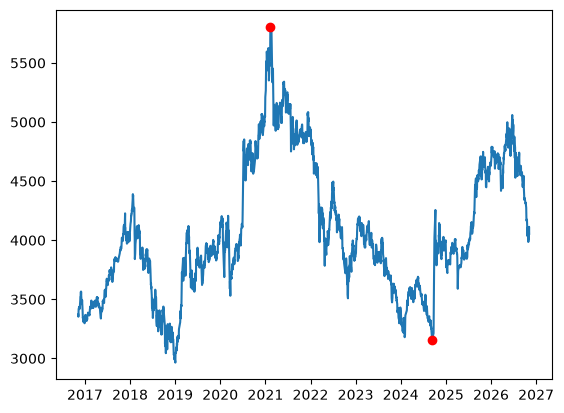

In [20]:
from datetime import datetime
from rqrisk import Risk
from dateutil.relativedelta import relativedelta
from rqdatac.validators import ensure_date_range
import matplotlib.pyplot as plt

In [ ]:
def show_max_drawdown(order_book_id, start_date, end_date):
    start_date, end_date = ensure_date_range(None, None, delta=relativedelta(years=10))
    prices = rqdatac.get_price(order_book_id, start_date, end_date, fields=["close"])["close"]
    prices.reset_index("order_book_id", inplace=True, drop=True)
    hist_high = prices.cummax()
    drawdown = 1 - prices / hist_high
    maxdd_low = drawdown.idxmax()
    maxdd_high = prices[prices.index < maxdd_low].idxmax()
    

    plt.figure()
    plt.plot(prices)
    plt.plot(maxdd_high, prices[maxdd_high], marker='o', c='red')
    plt.plot(maxdd_low, prices[maxdd_low], marker='o', c='red')
    plt.show()

In [14]:
prices[maxdd_low]

KeyError: Timestamp('2024-09-13 00:00:00')

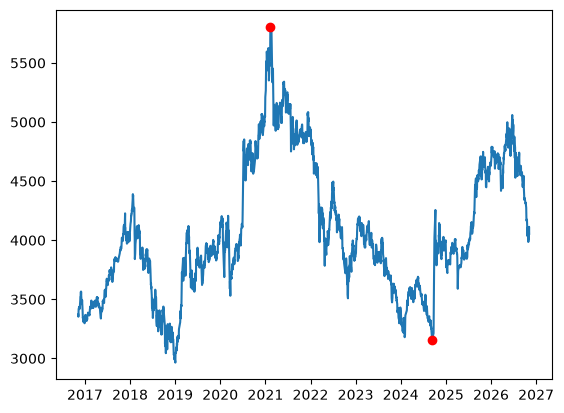

In [ ]:
import rqdatac
rqdatac.init()
import matplotlib as plt

df = rqdatac.get_price("000300.XSHG", start_date, end